# C1 · Clasificador con **CNN propia desde cero** (Propuesta 1)

Clasifica **recortes** de alimentos en las 323 clases con una red convolucional residual escrita a mano (con bloques *squeeze-excitation*), **sin pesos preentrenados de ningún tipo**. Es el clasificador de referencia «desde cero» frente a MobileNetV3, InceptionV3 y EfficientNetV2-S (C2–C4), que sí parten de ImageNet.

**Cómo se alimenta (todo desde tu Google Drive):**

| Archivo en Drive | Para qué |
|---|---|
| `food-prep-v21.zip` | Salida del 00: `classes.json`, `splits.json`, `crops_*.csv` y la carpeta **`crops/`** (los recortes; aquí **sí** se extraen) |
| `food_utils_final.py` | Utilidades comunes (se copia como `food_utils.py`) |

No necesita `food-recognition-2022.zip` (las fotos originales): C1 solo usa los recortes. El cuadernillo busca los archivos **por nombre** en tu Drive (carpeta `calorie_counter` y `MyDrive`, hasta 3 niveles) y, si no los encuentra, intenta bajarlos con `gdown`. Los zips se extraen en el disco local de Colab (`/content/data`); los **pesos, el historial y los resultados** se guardan en Drive.

**Qué hace**
1. Prepara los datos (busca, extrae y valida) y carga los recortes generados por el cuadernillo 00 (`prep.crops(split)`).
2. Entrena con AdamW, calentamiento + coseno, *label smoothing*, aumento (rotación, recorte, brillo/contraste, volteo), CutMix, *stochastic depth* y AMP. Cada época evalúa la **validación** (top-1), guarda en Drive `best.pt`, `last.pt` (+ copia `last_prev.pt`) e `history.csv` (para **reanudar** tras una desconexión) y aplica parada temprana.
3. Evalúa en **val** y **test** con las métricas comunes (`food_utils`): top-1, top-5, macro-F1, F1 por clase, confusiones más frecuentes e **intervalos de confianza por bootstrap**.
4. Guarda las probabilidades (`.npz`) y los pesos, mide parámetros, latencia y rendimiento, y escribe `resultados/C1_*.json`.

> **Modo piloto (`pilot=True`, por defecto).** 1 época con el 5 % de los recortes y 300 recortes de val/test: comprueba que todo funciona y estima el tiempo. Escribe en `resultados_pilot/`. Después, `pilot=False`.

> **Equidad.** Los cuatro clasificadores (C1–C4) usan **el mismo preprocesado** (`food_utils`: letterbox cuadrado a `imgsz`, mismo aumento, misma normalización), las **mismas particiones** y las mismas métricas. C1 parte de cero y los demás de ImageNet: **no son comparables como «misma condición»** y debe declararse en el informe. Esta evaluación usa recortes de **máscaras reales** (oráculo); el efecto de recortes de máscaras *predichas* se mide en el cuadernillo 99.

In [1]:
import os, sys, re, json, time, glob, random, shutil, subprocess, importlib
from pathlib import Path
import numpy as np

def ensure(pkg):
    try: importlib.import_module(pkg)
    except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
for p in ("gdown",): ensure(p)
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kw): return x

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")
    WORK = Path("/content/drive/MyDrive/calorie_counter")          # persiste entre sesiones (pesos, resultados)
    DATA = Path("/content/data")                                    # disco local: zips extraídos
elif Path("/kaggle/working").exists():
    WORK, DATA = Path("/kaggle/working/calorie_counter"), Path("/kaggle/working/data")
else:
    WORK, DATA = Path("./calorie_counter"), Path("./data")
WORK.mkdir(parents=True, exist_ok=True); DATA.mkdir(parents=True, exist_ok=True)
print("WORK (persistente):", WORK, "| DATA (local):", DATA)

Mounted at /content/drive
WORK (persistente): /content/drive/MyDrive/calorie_counter | DATA (local): /content/data


## 0. Datos desde Drive

Busca los tres archivos, extrae los dos zips en `DATA` (se omite si ya están extraídos en esta sesión) y localiza las carpetas que necesita `food_utils`. Si algún archivo tiene otro nombre o está en otra carpeta, indica su ruta en `DRIVE_PATHS`.

In [2]:
# Rutas explícitas (opcional). None = buscar por nombre en tu Drive.
DRIVE_PATHS = dict(prep=None, utils=None)
# Ids de los enlaces compartidos (solo se usan si el archivo no aparece en tu Drive montado)
DRIVE_IDS = dict(prep="1wuN5DRe7K3PrF-9JRn0I--5u1W2ByoDP", utils="1Uy62ABRj_a8EuwQG3RBrN5u1RF4tndwX")
PATTERNS  = dict(prep=r"food[-_ ]?prep[-_ ]?v21.*\.zip$", utils=r"^food_utils.*\.py$")
OUT_NAMES = dict(prep="food-prep-v21.zip", utils="food_utils.py")

def find_in_drive(kind, max_depth=3):
    pat = re.compile(PATTERNS[kind], re.I)
    roots = [WORK, Path("/content/drive/MyDrive"), Path.cwd()]
    for root in roots:
        if not root.exists(): continue
        base = len(root.parts)
        for dp, dn, fn in os.walk(root):
            dn[:] = [d for d in dn if not d.startswith(".") and d not in ("runs", "yolo_data", "predicciones", "resultados", "Trash")]
            if len(Path(dp).parts) - base >= max_depth: dn[:] = []
            for f in fn:
                if pat.search(f): return Path(dp) / f
    return None

def get_file(kind):
    if DRIVE_PATHS[kind]:
        p = Path(DRIVE_PATHS[kind]); assert p.exists(), f"No existe {p}"; return p
    p = find_in_drive(kind)
    if p: print(f"[{kind}] encontrado en Drive → {p}"); return p
    out = DATA / "zips" / OUT_NAMES[kind]; out.parent.mkdir(parents=True, exist_ok=True)
    print(f"[{kind}] no está en el Drive montado; intento bajarlo con gdown (id {DRIVE_IDS[kind]})...")
    import gdown
    r = gdown.download(id=DRIVE_IDS[kind], output=str(out), quiet=False)
    if not r or not out.exists():
        raise RuntimeError(f"No pude obtener '{kind}'. Copia el archivo a tu Drive (carpeta {WORK}) o indica su ruta en DRIVE_PATHS "
                           f"(gdown falla a menudo en archivos grandes por la cuota de descargas de Drive).")
    return out

def unzip_once(zpath, dest, exclude=()):
    zpath, dest = Path(zpath), Path(dest)
    marker, sig = dest / ".unzipped_ok", f"{zpath.name}:{zpath.stat().st_size}:{sorted(exclude)}"
    if marker.exists() and marker.read_text() == sig:
        print(f"   ya extraído en {dest}"); return
    dest.mkdir(parents=True, exist_ok=True)
    free, need = shutil.disk_usage(dest).free, zpath.stat().st_size
    print(f"   zip {need/1e9:.2f} GB | espacio libre {free/1e9:.1f} GB")
    if free < 1.5 * need: print("   ⚠️ poco espacio libre para extraer; si falla, usa un entorno con más disco")
    t0 = time.time()
    if shutil.which("unzip"):
        r = subprocess.run(["unzip", "-q", "-o", str(zpath), "-d", str(dest)] + (["-x", *exclude] if exclude else []))
        if r.returncode > 1: raise RuntimeError(f"unzip falló (código {r.returncode})")
    else:
        import zipfile, fnmatch
        with zipfile.ZipFile(zpath) as z:
            for n in tqdm(z.namelist(), desc="extrayendo"):
                if not any(fnmatch.fnmatch(n, p) for p in exclude): z.extract(n, dest)
    marker.write_text(sig); print(f"   extraído en {time.time()-t0:.0f} s")

def find_dir(root, pred, max_depth=5):
    root = Path(root); base = len(root.parts)
    for dp, dn, fn in os.walk(root):
        dn[:] = [d for d in dn if d != "images"]
        if len(Path(dp).parts) - base >= max_depth: dn[:] = []
        if pred(dn, fn): return Path(dp)
    return None

# 1) salida del cuadernillo 00, CON los recortes (C1 los necesita)
z_prep = get_file("prep"); print("→ extrayendo food-prep-v21 (con recortes; puede tardar unos minutos)"); unzip_once(z_prep, DATA / "prep")
PREP_DIR = find_dir(DATA / "prep", lambda dn, fn: "classes.json" in fn and "splits.json" in fn)
assert PREP_DIR is not None, "El zip de prep no contiene classes.json + splits.json"
missing = [f for f in ("manifest.json", "crops_train.csv", "crops_val.csv", "crops_test.csv") if not (PREP_DIR / f).exists()]
assert not missing, f"Faltan archivos en {PREP_DIR}: {missing}"
assert (PREP_DIR / "crops").exists(), f"Falta la carpeta de recortes {PREP_DIR / 'crops'}: ¿el zip es food-prep-v21 completo?"

# 2) food_utils
u = get_file("utils"); CODE = DATA / "code"; CODE.mkdir(exist_ok=True); shutil.copy(u, CODE / "food_utils.py")
sys.path.insert(0, str(CODE)); sys.modules.pop("food_utils", None)
print("\nPREP_DIR:", PREP_DIR, "\nutils   :", CODE / "food_utils.py")

[prep] no está en el Drive montado; intento bajarlo con gdown (id 1wuN5DRe7K3PrF-9JRn0I--5u1W2ByoDP)...


Downloading...
From (original): https://drive.google.com/uc?id=1wuN5DRe7K3PrF-9JRn0I--5u1W2ByoDP
From (redirected): https://drive.google.com/uc?id=1wuN5DRe7K3PrF-9JRn0I--5u1W2ByoDP&confirm=t&uuid=2ffaa34b-74bb-4c24-b731-8beef1375ba9
To: /content/data/zips/food-prep-v21.zip
100%|██████████| 2.46G/2.46G [00:28<00:00, 86.6MB/s]


→ extrayendo food-prep-v21 (con recortes; puede tardar unos minutos)
   zip 2.46 GB | espacio libre 204.9 GB
   extraído en 36 s
[utils] encontrado en Drive → /content/drive/MyDrive/calorie_counter_v/food_utils.py

PREP_DIR: /content/data/prep 
utils   : /content/data/code/food_utils.py


In [3]:
# Comprobar que el bloque de descarga se ejecutó antes
for _n in ("PREP_DIR", "CODE"):
    assert _n in globals(), f"Falta {_n}: ejecuta primero el bloque de descarga de datos (sección 0)."
assert (CODE / "food_utils.py").exists(), f"No está {CODE / 'food_utils.py'}"
if str(CODE) not in sys.path: sys.path.insert(0, str(CODE))
sys.modules.pop("food_utils", None)
import food_utils as fu

CFG = dict(
    base_id    = "C1",
    imgsz      = 160,         # MISMO valor en C1–C4
    batch      = 128,
    eval_batch = 256,
    epochs     = 40,
    patience   = 8,
    lr         = 2e-3,        # AdamW (batch 128)
    weight_decay = 0.05,
    warmup_iters = 300,
    label_smoothing = 0.1,
    aug_color  = 0.2,         # brillo y contraste: factor aleatorio en [1-x, 1+x] (0 = desactivado). MISMO valor en C1–C4
    aug_rot    = 15,          # rotación aleatoria en [-x, +x] grados (0 = desactivada). MISMO valor en C1–C4
    cutmix_prob = 0,        # fracción de lotes con CutMix (0 = desactivado)
    dropout    = 0.3,
    drop_path  = 0.1,         # profundidad estocástica (máximo, crece linealmente con la profundidad)
    widths     = (64, 128, 256, 512),
    blocks     = (2, 2, 2, 2),
    grad_clip  = 5.0,
    amp        = "auto",      # auto | bf16 | fp16 | off
    workers    = min(8, os.cpu_count() or 2),
    seed       = 42,
    n_boot     = 1000,
    log_every  = 100,
    pilot      = False,        # <-- False para el entrenamiento real
    prep_dir   = str(PREP_DIR),   # carpeta extraída por el bloque de descarga
)
CFG["exp_id"] = f"{CFG['base_id']}_cnn_propia"
RUN_NAME = CFG["exp_id"] + ("_pilot" if CFG["pilot"] else "")
print("food_utils", fu.__version__, "| Experimento:", RUN_NAME)

food_utils 0.1.0 | Experimento: C1_cnn_propia


In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
CUDA = torch.cuda.is_available()
DEVICE = "cuda" if CUDA else "cpu"
GPU = torch.cuda.get_device_name(0) if CUDA else "cpu"
AMP = CFG["amp"]
if AMP == "auto": AMP = ("bf16" if torch.cuda.is_bf16_supported() else "fp16") if CUDA else "off"
AMP_DTYPE = {"bf16": torch.bfloat16, "fp16": torch.float16}.get(AMP, torch.float16)
print("torch", torch.__version__, "| dispositivo:", GPU, "| AMP:", AMP)
if not CUDA: print("⚠️ Sin GPU: el entrenamiento real será muy lento. Activa una GPU.")

fu.set_seed(CFG["seed"])
prep = fu.Prep(CFG["prep_dir"])
print(prep.summary())
K = prep.K
CROPS = {s: prep.crops(s) for s in ("train", "val", "test")}
print({s: len(d) for s, d in CROPS.items()}, "recortes | clases:", K)
EPOCHS = 1 if CFG["pilot"] else CFG["epochs"]
TRAIN_LIMIT = int(0.05 * len(CROPS["train"])) if CFG["pilot"] else None
EVAL_LIMIT = 300 if CFG["pilot"] else None
FINAL_LIMIT = 300 if CFG["pilot"] else None
cnt = CROPS["train"].class_idx.value_counts()
print(f"Recortes por clase en train: mín {cnt.min()} | mediana {int(cnt.median())} | máx {cnt.max()} (clases con datos: {len(cnt)}/{K})")

# Comprobar que los recortes existen en disco (la extracción debe incluir la carpeta crops/)
for s, d in CROPS.items():
    need = {"file", "class_idx", "ann_id", "area_frac"} - set(d.columns)
    assert not need, f"crops_{s}.csv no tiene las columnas {need}"
    miss = [f for f in d["file"].sample(min(200, len(d)), random_state=0) if not Path(f).exists()]
    assert not miss, f"Faltan recortes de {s} (p. ej. {miss[0]}). Borra {DATA / 'prep'} y vuelve a ejecutar la sección 0."
print("✅ Recortes verificados en disco")

torch 2.11.0+cu130 | dispositivo: Tesla T4 | AMP: bf16
Prep[/content/data/prep] K=323 imagenes={'train': 35195, 'test': 3911, 'val': 946} anotaciones={'train': 66033, 'test': 7405, 'val': 1708} splits_hash=ce6d6fb977abcfd4
{'train': 65300, 'val': 1669, 'test': 7301} recortes | clases: 323
Recortes por clase en train: mín 21 | mediana 98 | máx 5142 (clases con datos: 323/323)
✅ Recortes verificados en disco


In [5]:
# food_utils (esta versión) no incluye CropDataset: se define aquí con su mismo preprocesado (letterbox cuadrado + normalización).
# IMPORTANTE para la equidad: C2–C4 deben usar exactamente esta clase (cópiala a food_utils.py o pega esta celda tal cual).
from PIL import Image, ImageEnhance
if not hasattr(fu, "CropDataset"):
    class CropDataset(torch.utils.data.Dataset):
        """Recortes -> (tensor [3,S,S] normalizado, class_idx, ann_id).
        Entrenamiento (todo aleatorio en cada lectura): rotación ±aug_rot° (p=0.5), recorte del 70–100 % de cada lado,
        brillo y contraste ±aug_color y volteo horizontal (p=0.5). Validación/test: solo letterbox, sin aleatoriedad."""
        MEAN_RGB = tuple(int(round(255 * m)) for m in fu.IMAGENET_MEAN)      # relleno de las esquinas = 0 tras normalizar (igual que el letterbox)
        def __init__(self, df, size, train=False):
            self.files, self.size, self.train = df["file"].tolist(), int(size), bool(train)
            self.y = df["class_idx"].to_numpy(np.int64); self.ids = df["ann_id"].to_numpy(np.int64)
            self.color, self.rot = float(CFG.get("aug_color", 0.2)), float(CFG.get("aug_rot", 15))
        def __len__(self): return len(self.files)
        def __getitem__(self, i):
            with Image.open(self.files[i]) as im: img = im.convert("RGB")
            hflip = False
            if self.train:
                if self.rot > 0 and random.random() < 0.5:
                    img = img.rotate(random.uniform(-self.rot, self.rot), resample=Image.BILINEAR, expand=True, fillcolor=self.MEAN_RGB)
                W, H = img.size; cw, ch = max(8, int(W * random.uniform(0.7, 1.0))), max(8, int(H * random.uniform(0.7, 1.0)))
                x0, y0 = random.randint(0, max(0, W - cw)), random.randint(0, max(0, H - ch))
                img = img.crop((x0, y0, min(W, x0 + cw), min(H, y0 + ch)))
                if self.color > 0:
                    img = ImageEnhance.Brightness(img).enhance(random.uniform(1 - self.color, 1 + self.color))
                    img = ImageEnhance.Contrast(img).enhance(random.uniform(1 - self.color, 1 + self.color))
                hflip = random.random() < 0.5
            pv, _, _ = fu.letterbox_image(img, self.size, hflip=hflip)
            return torch.from_numpy(pv), int(self.y[i]), int(self.ids[i])
    fu.CropDataset = CropDataset
    print("CropDataset definido en el cuadernillo (food_utils no lo trae).")
else:
    print("Se usa fu.CropDataset de food_utils.")
_t = fu.CropDataset(CROPS["val"].head(2), CFG["imgsz"], train=True)[0]; print("Muestra:", tuple(_t[0].shape), "clase", _t[1])

CropDataset definido en el cuadernillo (food_utils no lo trae).
Muestra: (3, 160, 160) clase 223


## 1. Modelo, datos y bucle de entrenamiento

**FoodNet:** tallo de 2 convoluciones (la primera con *stride* 2) + 4 etapas de bloques residuales con *squeeze-excitation* (anchos 64→512, *stride* 2 al inicio de cada etapa salvo la primera) + *global average pooling* + *dropout* + capa lineal. Inicialización Kaiming y la última BN de cada bloque a cero (entrena más estable desde cero).

In [6]:
def autocast():
    return torch.autocast(device_type="cuda", dtype=AMP_DTYPE, enabled=(AMP != "off" and CUDA))

class SE(nn.Module):
    def __init__(self, c, r=16):
        super().__init__(); h = max(8, c // r)
        self.fc1, self.fc2 = nn.Conv2d(c, h, 1), nn.Conv2d(h, c, 1)
    def forward(self, x):
        s = x.mean((2, 3), keepdim=True)
        return x * torch.sigmoid(self.fc2(F.relu(self.fc1(s))))

class Block(nn.Module):
    def __init__(self, cin, cout, stride, drop_path=0.0):
        super().__init__()
        self.c1, self.b1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False), nn.BatchNorm2d(cout)
        self.c2, self.b2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False), nn.BatchNorm2d(cout)
        self.se = SE(cout)
        self.short = None if (stride == 1 and cin == cout) else nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
        self.drop_path = drop_path
    def forward(self, x):
        y = self.se(self.b2(self.c2(F.relu(self.b1(self.c1(x)), inplace=True))))
        if self.training and self.drop_path > 0:
            keep = 1.0 - self.drop_path
            y = y * ((torch.rand(x.size(0), 1, 1, 1, device=x.device) < keep).to(y.dtype) / keep)
        return F.relu(y + (x if self.short is None else self.short(x)), inplace=True)

class FoodNet(nn.Module):
    def __init__(self, num_classes, widths=(64, 128, 256, 512), blocks=(2, 2, 2, 2), dropout=0.3, drop_path=0.1):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 32, 3, 2, 1, bias=False), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
                                  nn.Conv2d(32, widths[0], 3, 1, 1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU(inplace=True))
        total, k, cin, layers = sum(blocks), 0, widths[0], []
        for i, (w, n) in enumerate(zip(widths, blocks)):
            for j in range(n):
                layers.append(Block(cin, w, 2 if (j == 0 and i > 0) else 1, drop_path * k / max(1, total - 1))); cin = w; k += 1
        self.stages = nn.Sequential(*layers)
        self.drop, self.fc = nn.Dropout(dropout), nn.Linear(cin, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d): nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
        for m in self.modules():
            if isinstance(m, Block): nn.init.zeros_(m.b2.weight)
    def forward(self, x):
        return self.fc(self.drop(self.stages(self.stem(x)).mean((2, 3))))

def build_model():
    return FoodNet(K, CFG["widths"], CFG["blocks"], CFG["dropout"], CFG["drop_path"]).to(DEVICE).to(memory_format=torch.channels_last)

def _to_dev(x): return x.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last)

def make_train_loader():
    df = CROPS["train"]
    if TRAIN_LIMIT: df = df.sample(TRAIN_LIMIT, random_state=CFG["seed"])
    return DataLoader(fu.CropDataset(df, CFG["imgsz"], train=True), batch_size=CFG["batch"], shuffle=True, num_workers=CFG["workers"],
                      drop_last=True, pin_memory=CUDA, persistent_workers=CFG["workers"] > 0)

def build_optimizer(model):
    decay = [p for p in model.parameters() if p.requires_grad and p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.requires_grad and p.ndim <= 1]
    return torch.optim.AdamW([dict(params=decay, weight_decay=CFG["weight_decay"]), dict(params=no_decay, weight_decay=0.0)], lr=CFG["lr"])

def build_scheduler(optimizer, total_steps):
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: fu.warmup_cosine(s, total_steps, CFG["warmup_iters"]))

def build_scaler():
    try: return torch.amp.GradScaler("cuda", enabled=(AMP == "fp16"))
    except (AttributeError, TypeError): return torch.cuda.amp.GradScaler(enabled=(AMP == "fp16"))

def save_ckpt(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp"); torch.save(obj, tmp); os.replace(tmp, path)

def load_ckpt(path):
    try: return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError: return torch.load(path, map_location="cpu")

def train_one_epoch(model, loader, optimizer, scheduler, scaler, epoch):
    model.train(); crit = nn.CrossEntropyLoss(label_smoothing=CFG["label_smoothing"]); tot, n, t0 = 0.0, 0, time.time()
    for it, (x, y, _) in enumerate(loader):
        x, y = _to_dev(x), y.to(DEVICE, non_blocking=True)
        cut = CFG["cutmix_prob"] > 0 and random.random() < CFG["cutmix_prob"]
        if cut:                                                      # CutMix: pega un parche de otra imagen del lote
            lam = float(np.random.beta(1.0, 1.0)); idx = torch.randperm(x.size(0), device=x.device)
            H, W = x.shape[2], x.shape[3]; rh, rw = int(H * np.sqrt(1 - lam)), int(W * np.sqrt(1 - lam))
            cy, cx = np.random.randint(H), np.random.randint(W)
            y0, y1, x0, x1 = max(cy - rh // 2, 0), min(cy + rh // 2, H), max(cx - rw // 2, 0), min(cx + rw // 2, W)
            x[:, :, y0:y1, x0:x1] = x[idx, :, y0:y1, x0:x1]
            lam = 1.0 - (y1 - y0) * (x1 - x0) / (H * W)
        with autocast():
            out = model(x)
            loss = lam * crit(out, y) + (1 - lam) * crit(out, y[idx]) if cut else crit(out, y)
        optimizer.zero_grad(set_to_none=True)
        if not torch.isfinite(loss):
            print(f"  ⚠️ pérdida no finita en la iteración {it}; se omite"); scheduler.step(); continue
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        scaler.step(optimizer); scaler.update(); scheduler.step()
        tot += float(loss); n += 1
        if (it + 1) % CFG["log_every"] == 0:
            print(f"  época {epoch} it {it+1}/{len(loader)} | pérdida {tot/max(1,n):.3f} | lr {optimizer.param_groups[0]['lr']:.2e} | {time.time()-t0:.0f} s")
    return tot / max(1, n)

@torch.no_grad()
def predict_probs(model, split, limit=None):
    model.eval(); df = CROPS[split]
    if limit: df = df.sample(min(limit, len(df)), random_state=0)
    dl = DataLoader(fu.CropDataset(df, CFG["imgsz"], train=False), batch_size=CFG["eval_batch"], shuffle=False, num_workers=CFG["workers"])
    ids, ys, ps = [], [], []
    for x, y, aid in dl:
        with autocast(): logits = model(_to_dev(x))
        ps.append(logits.float().softmax(-1).cpu().numpy()); ys.append(y.numpy()); ids.append(aid.numpy())
    return np.concatenate(ids), np.concatenate(ys), np.concatenate(ps)

def evaluate_val(model):
    ids, y, p = predict_probs(model, "val", limit=EVAL_LIMIT)
    m = fu.classification_metrics(y, p)
    print(f"    val: top1 {m['top1']:.4f} | top5 {m['top5']:.4f} | macro-F1 {m['macro_f1']:.4f}")
    return m["top1"]

## 2. Entrenamiento con reanudación segura

`last.pt` guarda modelo, optimizador, planificador, escalador, historial y parada temprana; si existe pero no hay `DONE.json` se **reanuda**. Con `DONE.json` no se entrena de nuevo.

In [7]:
RUN_DIR = WORK / "runs" / RUN_NAME                      # en Drive: sobrevive a las desconexiones
RUN_DIR.mkdir(parents=True, exist_ok=True)
CK_LAST, CK_PREV, CK_BEST, DONE = RUN_DIR / "last.pt", RUN_DIR / "last_prev.pt", RUN_DIR / "best.pt", RUN_DIR / "DONE.json"
HIST_CSV = RUN_DIR / "history.csv"
(RUN_DIR / "config.json").write_text(json.dumps(CFG, indent=1, default=str))
KEY_CFG = ("imgsz", "batch", "epochs", "lr", "weight_decay", "widths", "blocks", "label_smoothing", "cutmix_prob", "dropout", "drop_path", "aug_color", "aug_rot", "seed")

def save_last(obj):
    """Rota last.pt -> last_prev.pt y escribe el nuevo de forma atómica: siempre queda un punto de reanudación válido."""
    if CK_LAST.exists(): os.replace(CK_LAST, CK_PREV)
    save_ckpt(CK_LAST, obj)

def load_last():
    for p in (CK_LAST, CK_PREV):
        if p.exists():
            try:
                ck = load_ckpt(p); print(f"↻ Punto de reanudación: {p.name} (época {ck['epoch']+1} completada)"); return ck
            except Exception as e:
                print(f"⚠️ {p.name} ilegible ({type(e).__name__}: {e}); pruebo la copia anterior")
                if p == CK_LAST: CK_LAST.unlink()            # evita que una copia corrupta pise la buena al rotar
    return None

def run_training():
    model = build_model()
    optimizer = build_optimizer(model)
    loader = make_train_loader()
    scheduler, scaler = build_scheduler(optimizer, EPOCHS * len(loader)), build_scaler()
    stopper, history, start = fu.EarlyStopper(CFG["patience"]), [], 0
    ck = load_last()
    if ck is not None:
        model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
        scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"])
        stopper.load_state_dict(ck["stopper"]); history, start = ck["history"], ck["epoch"] + 1
        diff = [k for k in KEY_CFG if ck.get("cfg") and str(ck["cfg"].get(k)) != str(CFG.get(k))]
        if diff: print("⚠️ CFG distinto del run original en", diff, "→ se usan los valores actuales (restaura los originales para reproducir fielmente)")
        print(f"   continúa en la época {start+1}/{EPOCHS} ({len(history)} ya hechas)")
    for epoch in range(start, EPOCHS):
        if stopper.should_stop: print("Parada temprana ya alcanzada antes del corte."); break
        t0 = time.time()
        loss = train_one_epoch(model, loader, optimizer, scheduler, scaler, epoch)
        t_train = time.time() - t0
        val_top1 = evaluate_val(model)
        improved = stopper.update(val_top1)
        if improved: save_ckpt(CK_BEST, dict(model=model.state_dict(), epoch=epoch, val_top1=val_top1))
        history.append(dict(epoch=epoch, loss=float(loss), val_top1=float(val_top1), lr=float(optimizer.param_groups[0]["lr"]),
                            train_s=round(t_train, 1), time_s=round(time.time() - t0, 1)))
        save_last(dict(model=model.state_dict(), optimizer=optimizer.state_dict(), scheduler=scheduler.state_dict(),
                       scaler=scaler.state_dict(), stopper=stopper.state_dict(), history=history, epoch=epoch,
                       cfg={k: CFG[k] for k in KEY_CFG}))
        pd.DataFrame(history).to_csv(HIST_CSV, index=False)             # historial legible, en Drive, tras cada época
        print(f"Época {epoch+1}/{EPOCHS} | pérdida {loss:.3f} | top-1 val {val_top1:.4f}{' ★' if improved else ''} | "
              f"{history[-1]['time_s']:.0f} s (entrenar {t_train:.0f} s) | 💾 guardado en Drive")
        if stopper.should_stop: print(f"Parada temprana: sin mejora en {CFG['patience']} épocas (mejor: época {stopper.best_epoch+1})"); break
    return history, stopper

import pandas as pd
if DONE.exists():
    print("✅ Entrenamiento ya terminado:", DONE.read_text()[:300])
else:
    history, stopper = run_training()
    DONE.write_text(json.dumps(dict(time_s=round(sum(h["time_s"] for h in history), 1), epochs_run=len(history),
                                    best_epoch=stopper.best_epoch, best_val_top1=stopper.best, pilot=CFG["pilot"],
                                    finished=time.strftime("%Y-%m-%d %H:%M:%S"))))
    if CFG["pilot"] and history:
        est = history[-1]["train_s"] / 0.05 / 60
        print(f"≈ {est:.1f} min de ENTRENAMIENTO por época con todos los recortes (+ validación) → {CFG['epochs']} épocas ≈ {est*CFG['epochs']/60:.1f} h")
INFO = json.loads(DONE.read_text()); assert CK_BEST.exists(), f"No existe {CK_BEST}"
print("Entrenamiento:", INFO)
if CUDA: torch.cuda.empty_cache()

↻ Punto de reanudación: last.pt (época 32 completada)
   continúa en la época 33/40 (32 ya hechas)


/tmp/ipykernel_725/544502831.py:98: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  tot += float(loss); n += 1


  época 32 it 100/510 | pérdida 1.846 | lr 1.87e-04 | 218 s
  época 32 it 200/510 | pérdida 1.851 | lr 1.78e-04 | 436 s
  época 32 it 300/510 | pérdida 1.847 | lr 1.70e-04 | 654 s
  época 32 it 400/510 | pérdida 1.846 | lr 1.61e-04 | 872 s
  época 32 it 500/510 | pérdida 1.847 | lr 1.53e-04 | 1090 s
    val: top1 0.4374 | top5 0.7478 | macro-F1 0.2444
Época 33/40 | pérdida 1.847 | top-1 val 0.4374 | 1121 s (entrenar 1111 s) | 💾 guardado en Drive
  época 33 it 100/510 | pérdida 1.820 | lr 1.44e-04 | 219 s
  época 33 it 200/510 | pérdida 1.816 | lr 1.36e-04 | 437 s
  época 33 it 300/510 | pérdida 1.814 | lr 1.28e-04 | 655 s
  época 33 it 400/510 | pérdida 1.822 | lr 1.20e-04 | 873 s
  época 33 it 500/510 | pérdida 1.822 | lr 1.13e-04 | 1091 s
    val: top1 0.4464 | top5 0.7579 | macro-F1 0.2505
Época 34/40 | pérdida 1.823 | top-1 val 0.4464 | 1122 s (entrenar 1113 s) | 💾 guardado en Drive
  época 34 it 100/510 | pérdida 1.822 | lr 1.05e-04 | 219 s
  época 34 it 200/510 | pérdida 1.811 | 

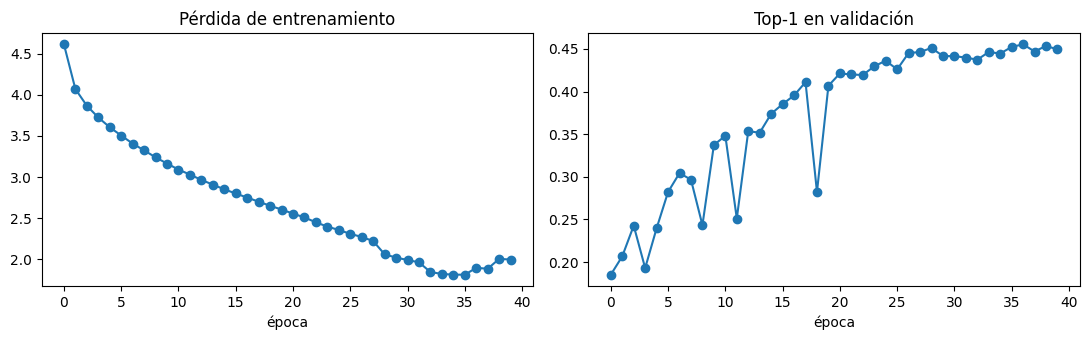

In [8]:
# Curvas de entrenamiento (desde history.csv en Drive; si no existe, desde last.pt)
try:
    import matplotlib.pyplot as plt
    hist = pd.read_csv(HIST_CSV).to_dict("records") if HIST_CSV.exists() else load_last()["history"]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot([h["loss"] for h in hist], marker="o"); ax[0].set_title("Pérdida de entrenamiento")
    ax[1].plot([h["val_top1"] for h in hist], marker="o"); ax[1].set_title("Top-1 en validación")
    for a in ax: a.set_xlabel("época")
    plt.tight_layout(); plt.savefig(RUN_DIR / "curvas.png", dpi=130); plt.show()
except Exception as e:
    print("Sin curvas:", type(e).__name__, e)

---
### ✅ Fin del entrenamiento

Aquí termina la parte de **entrenamiento**: los pesos quedan en `{WORK}/runs/{RUN_NAME}/best.pt` y el historial en `history.csv` (en tu Drive). Las secciones 3–5 siguientes (evaluación, eficiencia y `resultados/C1_*.json`) se pueden ejecutar después y repetir sin reentrenar: el marcador `DONE.json` evita volver a entrenar.

## 3. Evaluación (val y test)

Se carga `best.pt`. Métricas comunes de `food_utils`: top-1, top-5, macro-F1 y recall balanceado (promedios sobre las clases con soporte), F1 por clase y confusiones más frecuentes; en test, además, **intervalos de confianza por bootstrap**. Las probabilidades se guardan para el pipeline (cuadernillo 99).

In [9]:
PRED_DIR = WORK / ("predicciones_pilot" if CFG["pilot"] else "predicciones"); PRED_DIR.mkdir(parents=True, exist_ok=True)
model = build_model()
model.load_state_dict(load_ckpt(CK_BEST)["model"]); model.eval()

METRICS, OUTS, OUT_FILES = {}, {}, {}
for s in ("val", "test"):
    t0 = time.time()
    ids, y, p = predict_probs(model, s, limit=FINAL_LIMIT)
    m = fu.classification_metrics(y, p, names=prep.names)
    if s == "test": m["bootstrap_ci"] = fu.bootstrap_ci(y, p, n_boot=(100 if CFG["pilot"] else CFG["n_boot"]), seed=CFG["seed"])
    METRICS[s], OUTS[s] = m, (ids, y, p)
    OUT_FILES[s] = str(fu.save_classifier_outputs(PRED_DIR / f"{RUN_NAME}_{s}.npz", ids, y, p))
    print(f"[{s}] n={m['n']:,} | top-1 {m['top1']:.4f} | top-5 {m['top5']:.4f} | macro-F1 {m['macro_f1']:.4f} | recall balanceado {m['balanced_acc']:.4f} | {time.time()-t0:.0f} s")
ci = METRICS["test"]["bootstrap_ci"]
print("IC 95 % (test):", {k: f"{v['mean']:.3f} [{v['lo']:.3f}, {v['hi']:.3f}]" for k, v in ci.items()})
print("\nConfusiones más frecuentes (test):")
for c in METRICS["test"]["top_confusions"][:8]: print(f"  {c['true']}  →  {c['pred']}  ({c['count']})")

# Estadísticas completas en Drive (por clase, matriz de confusión completa y todas las métricas)
import pandas as pd
for s in ("val", "test"):
    pd.DataFrame(METRICS[s]["per_class"]).to_csv(PRED_DIR / f"{RUN_NAME}_{s}_por_clase.csv", index=False)
    _, y_, p_ = OUTS[s]
    np.savez_compressed(PRED_DIR / f"{RUN_NAME}_{s}_confusion.npz", cm=np.bincount(np.asarray(y_) * K + p_.argmax(1), minlength=K * K).reshape(K, K),
                        names=np.array(prep.names))
(PRED_DIR / f"{RUN_NAME}_metricas.json").write_text(json.dumps(fu._jsonable(METRICS), indent=1, ensure_ascii=False))
print("Estadísticas guardadas en:", PRED_DIR)

# Sensibilidad al tamaño relativo de la instancia (area_frac), con los recortes de test evaluados
ids, y, p = OUTS["test"]; hit = pd.Series((p.argmax(1) == y).astype(float), index=ids)
tdf = CROPS["test"].set_index("ann_id").loc[ids]
tdf["hit"] = hit.values
try:
    tdf["tamaño"] = pd.qcut(tdf["area_frac"], 4, labels=["Q1 pequeña", "Q2", "Q3", "Q4 grande"], duplicates="drop")
    print("\nTop-1 por tamaño relativo de la instancia (test):"); print(tdf.groupby("tamaño", observed=True)["hit"].agg(["mean", "count"]).round(3).to_string())
except Exception as e:
    print("Sin análisis por tamaño:", type(e).__name__, e)

[val] n=1,669 | top-1 0.4554 | top-5 0.7585 | macro-F1 0.2582 | recall balanceado 0.2721 | 10 s
[test] n=7,301 | top-1 0.5055 | top-5 0.7762 | macro-F1 0.3082 | recall balanceado 0.3004 | 38 s
IC 95 % (test): {'top1': '0.506 [0.493, 0.517]', 'top5': '0.776 [0.767, 0.785]', 'macro_f1': '0.303 [0.289, 0.315]'}

Confusiones más frecuentes (test):
  espresso  →  coffee  (39)
  white_coffee  →  coffee  (29)
  bread  →  bread_wholemeal  (27)
  bread  →  bread_white  (25)
  mixed_salad_chopped_without_sauce  →  salad_leaf_salad_green  (24)
  honey  →  butter  (21)
  bread_whole_wheat  →  bread_wholemeal  (21)
  coffee  →  espresso  (17)
Estadísticas guardadas en: /content/drive/MyDrive/calorie_counter/predicciones

Top-1 por tamaño relativo de la instancia (test):
             mean  count
tamaño                  
Q1 pequeña  0.433   1827
Q2          0.495   1824
Q3          0.549   1827
Q4 grande   0.546   1823


## 4. Eficiencia

Solo el **clasificador**: pasada hacia delante con 1 recorte ya preprocesado (latencia) y con un lote de 128 (rendimiento), en la GPU de esta sesión. En el pipeline completo el coste es *segmentador + N × clasificador* (N = alimentos del plato). Solo comparable entre modelos medidos en la **misma GPU**.

In [10]:
S = CFG["imgsz"]; x1 = torch.randn(1, 3, S, S, device=DEVICE).to(memory_format=torch.channels_last)
xb = torch.randn(128, 3, S, S, device=DEVICE).to(memory_format=torch.channels_last)
@torch.no_grad()
def fwd1():
    with autocast(): model(x1)
@torch.no_grad()
def fwdb():
    with autocast(): model(xb)
fu.reset_gpu_peak()
LAT = fu.measure_latency(fwd1, warmup=20, iters=100)
THR = fu.measure_latency(fwdb, warmup=5, iters=20)
EFF = dict(params=fu.count_params(model), latency=LAT, throughput_img_s=128 / (THR["mean_ms"] / 1000), gpu_mem_mb=fu.gpu_memory_mb(),
           gpu=GPU, imgsz=S, precision=AMP, scope="forward del clasificador (batch 1 / batch 128), sin carga de imagen")
print(f"Parámetros: {EFF['params']/1e6:.2f} M | latencia (batch 1): {LAT['mean_ms']:.2f} ± {LAT['std_ms']:.2f} ms | rendimiento: {EFF['throughput_img_s']:,.0f} img/s en {GPU} [{AMP}]")

Parámetros: 11.44 M | latencia (batch 1): 6.87 ± 0.80 ms | rendimiento: 208 img/s en Tesla T4 [bf16]


## 5. Guardar resultados

In [11]:
OUT_RES = WORK / ("resultados_pilot" if CFG["pilot"] else "resultados")
res_path = fu.write_result(
    RUN_NAME, model="FoodNet (CNN propia, desde cero)", metrics=METRICS, prep=prep, cfg=CFG, seed=CFG["seed"], efficiency=EFF,
    train=dict(pretrained=False, epochs_run=INFO.get("epochs_run"), epochs_max=CFG["epochs"], best_epoch=INFO.get("best_epoch"),
               best_val_top1=INFO.get("best_val_top1"), time_s=INFO.get("time_s"), batch=CFG["batch"], lr=CFG["lr"], amp=AMP,
               n_train=len(CROPS["train"]), pilot=CFG["pilot"]),
    files=dict(weights=str(CK_BEST), probs_val=OUT_FILES["val"], probs_test=OUT_FILES["test"]),
    notes="Clasificador de recortes de mascaras reales (oraculo). Sin preentrenamiento.", out_dir=OUT_RES)
print("Resultado guardado en:", res_path)
if CFG["pilot"]:
    print("\n✅ PILOTO COMPLETO: el flujo funciona de extremo a extremo. Pon CFG['pilot']=False y vuelve a ejecutar todo el cuadernillo.")

Resultado guardado en: /content/drive/MyDrive/calorie_counter/resultados/C1_cnn_propia.json


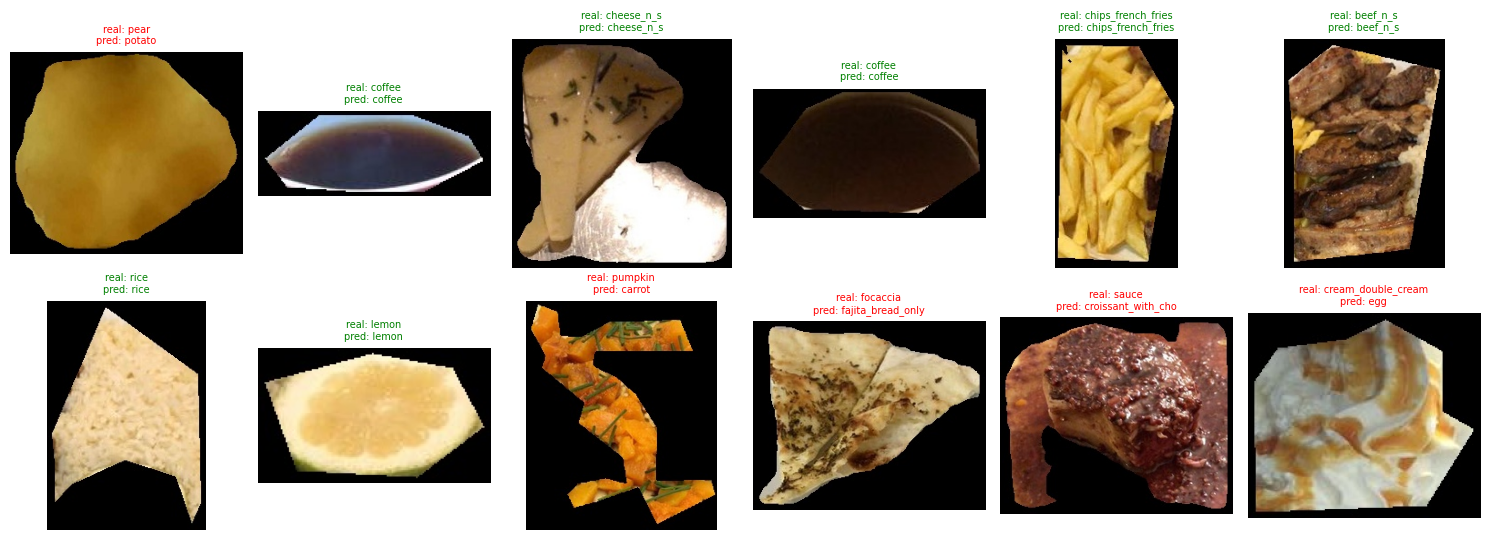

In [12]:
# Revisión cualitativa: 12 recortes de test con la clase real (verde = acierto, rojo = error)
try:
    import matplotlib.pyplot as plt
    from PIL import Image
    ids, y, p = OUTS["test"]; rows = CROPS["test"].set_index("ann_id").loc[ids[:12]]
    fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
    for ax, (aid, r), yi, pi in zip(axes.flat, rows.iterrows(), y[:12], p[:12]):
        ax.imshow(Image.open(r["file"])); ax.axis("off")
        ax.set_title(f"real: {prep.names[yi][:18]}\npred: {prep.names[int(pi.argmax())][:18]}", fontsize=7, color=("green" if pi.argmax() == yi else "red"))
    plt.tight_layout(); plt.show()
except Exception as e:
    print("Sin vista cualitativa:", type(e).__name__, e)

### Siguientes pasos
- Si el piloto salió bien: `CFG["pilot"] = False` y **Ejecutar todo**. Si Colab se desconecta, vuelve a ejecutar de arriba abajo: los recortes se vuelven a extraer en el disco local (unos minutos) y el entrenamiento **se reanuda solo** desde `last.pt` (o `last_prev.pt` si el último estuviera dañado) en Drive. Mantén el mismo `CFG` para no cambiar el `RUN_NAME`.
- Después: C2 (MobileNetV3), C3 (InceptionV3) y C4 (EfficientNetV2-S) con el **mismo preprocesado y métricas** (usa la misma clase `CropDataset`).
- Dónde queda todo (en `{WORK}`): `runs/C1_cnn_propia/` (pesos, `history.csv`, `curvas.png`), `predicciones/` (probabilidades `.npz`, métricas por clase, matriz de confusión completa, `_metricas.json`) y `resultados/C1_cnn_propia.json` (lo que lee el cuadernillo 99).